Rentang tanggal: 2013-01-01 00:00:00 s/d 2017-12-31 00:00:00
Total hari: 1826


,store,item,sales
date,,,
2013-01-01,1,1,13
2013-01-02,1,1,11
2013-01-03,1,1,14
2013-01-04,1,1,13
2013-01-05,1,1,10


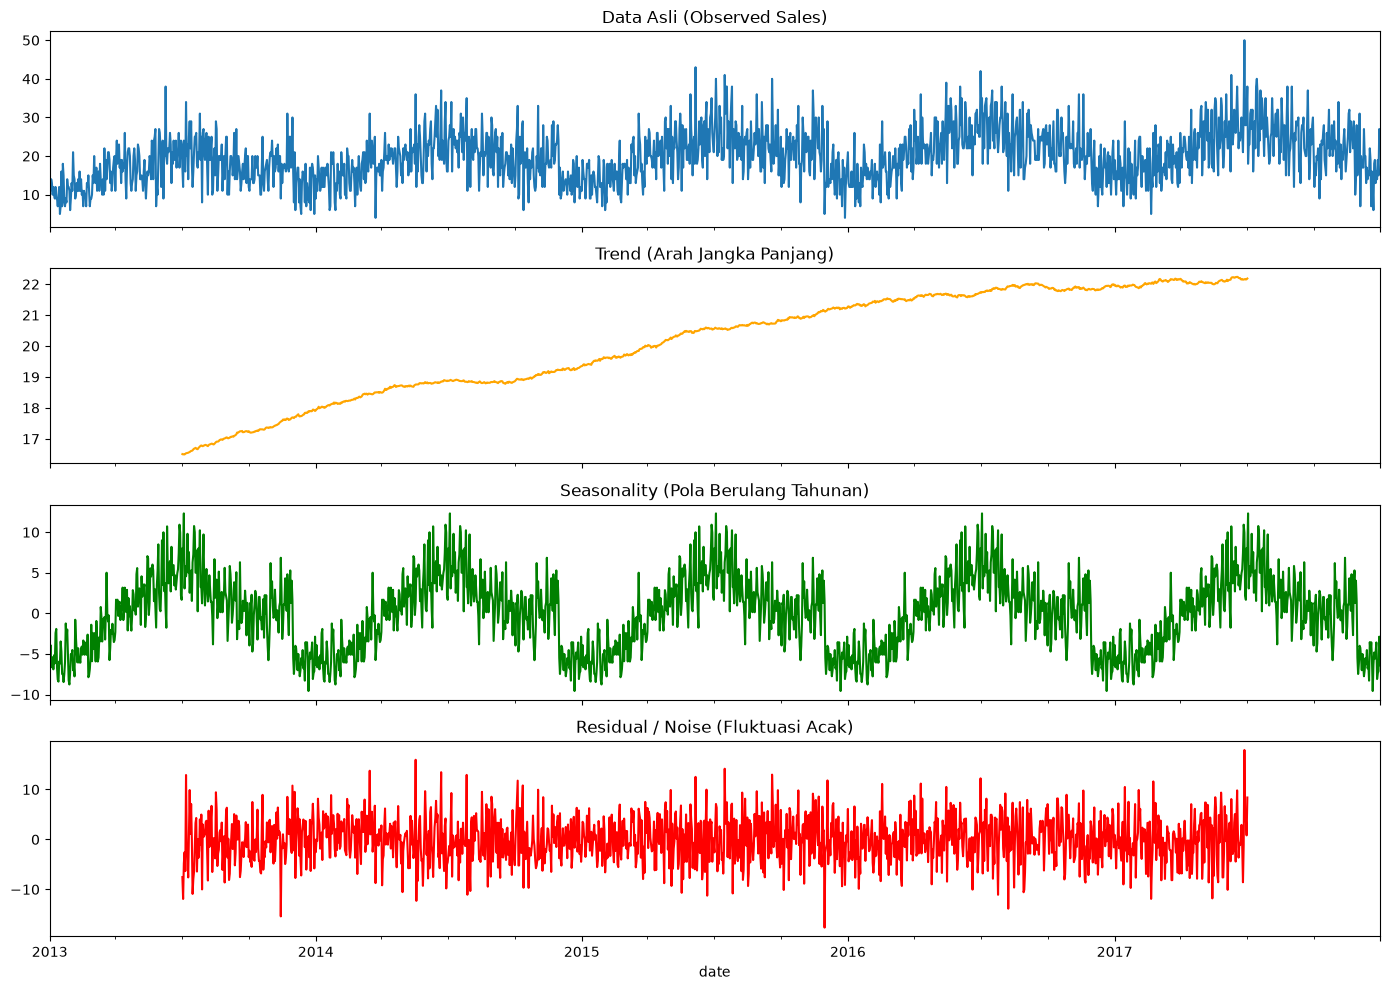

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Load data
df = pd.read_csv('../data/raw/train.csv')
df['date'] = pd.to_datetime(df['date'])

# 2. Filter spesifik: Store 1, Item 1
df_sample = df[(df['store'] == 1) & (df['item'] == 1)].copy()
df_sample = df_sample.sort_values('date').set_index('date')

print(f"Rentang tanggal: {df_sample.index.min()} s/d {df_sample.index.max()}")
print(f"Total hari: {len(df_sample)}")
display(df_sample.head())

# 3. Seasonal Decomposition (Periode 365 hari untuk melihat pola tahunan)
decomposition = seasonal_decompose(df_sample['sales'], model='additive', period=365)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

decomposition.observed.plot(ax=axes[0], title='Data Asli (Observed Sales)')
decomposition.trend.plot(ax=axes[1], title='Trend (Arah Jangka Panjang)', color='orange')
decomposition.seasonal.plot(ax=axes[2], title='Seasonality (Pola Berulang Tahunan)', color='green')
decomposition.resid.plot(ax=axes[3], title='Residual / Noise (Fluktuasi Acak)', color='red')

plt.tight_layout()
plt.show()